In [19]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from loguru import logger

# ==================== 子图 ====================
class SubState(TypedDict):
    data: str

def sub_node(state: SubState) -> Command:
    """子图节点：执行后动态路由回父图的 parent_router"""
    logger.info("[子图] sub_node 执行")
    return Command(
        update={"data": state["data"] + " → 子图"},
        goto="node_b",       # 路由到父图节点
        graph=Command.PARENT,       # 指定目标为父图
    )

sub_builder = StateGraph(state_schema=SubState)
sub_builder.add_node("sub_node", sub_node)
sub_builder.add_edge(START, "sub_node")

sub_graph = sub_builder.compile()

# ==================== 父图 ====================
class ParentState(TypedDict):
    data: str

def node_a(state: ParentState) -> ParentState:
    logger.info("[父图] node_a 执行")
    return {"visited_a": True}

def node_b(state: ParentState) -> ParentState:
    logger.info("[父图] node_b 执行")
    return {"visited_b": True}

parent_builder = StateGraph(state_schema=ParentState)
parent_builder.add_node(
    "sub_graph", sub_graph
)
parent_builder.add_node("node_a", node_a)
parent_builder.add_node("node_b", node_b)
parent_builder.add_edge(START, "sub_graph")
parent_builder.add_edge("sub_graph", "node_a")
parent_builder.add_edge("node_a", "node_b")
parent_builder.add_edge("node_b", END)

parent_graph = parent_builder.compile()

result = parent_graph.invoke({"data": "初始"})
print(f"\n最终结果: {result}")

2026-10-30 13:38:57.385 | INFO     | __main__:sub_node:12 - [子图] sub_node 执行
2026-10-30 13:38:57.386 | INFO     | __main__:node_a:30 - [父图] node_a 执行
2026-10-30 13:38:57.407 | INFO     | __main__:node_b:34 - [父图] node_b 执行
2026-10-30 13:38:57.412 | INFO     | __main__:node_b:34 - [父图] node_b 执行



最终结果: {'data': '初始 → 子图'}


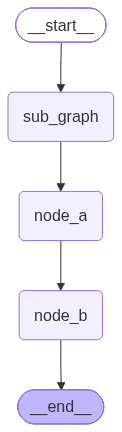

In [20]:
from IPython.display import display
display(parent_graph)